# 실습 02 · IoU·일대일 매칭

> **Day15 | 객체탐지·YOLO·추적 · 01_기본필수**
> 원본 스크립트: `02_iou.py` · 교안 PPT 27쪽 · 직접 구현: B02, B03
> 결과: 이 노트북을 실제 실행한 출력

## 학습 목표

- IoU = 교집합 / 합집합을 손으로 계산하고 코드 결과와 맞춘다.
- confidence 순서로 같은 클래스의 미사용 정답에만 연결하는 일대일 매칭을 구현한다.
- 중복 박스가 FP가 되는 이유를 설명한다.

## 핵심 개념

| 개념 | 설명 |
|---|---|
| IoU | 두 박스가 겹친 정도 0~1 (위치 품질) |
| confidence | 모델이 매긴 점수 (확신 정도), IoU와 다른 축 |
| TP / FP / FN | 맞힌 예측 / 틀린·중복 예측 / 놓친 정답 |
| 일대일 매칭 | 정답 하나는 TP를 한 번만 만든다 |

## 0. 준비

- 이 노트북은 `01_기본필수` 폴더(같은 폴더에 `data/`가 있는 위치)에서 연다.
- 입력은 `data/`의 원본을 읽기만 하고, 노트북이 만드는 결과 파일은 `outputs_notebook/`에 저장한다.
- CPU에서 실행한다. GPU·CUDA 코드는 없다.

In [1]:
# ============================================================
# 0. 라이브러리·경로 설정
# ============================================================
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# BASE : 노트북 폴더(01_기본필수) / DATA : 원본 입력 / OUT : 노트북 결과 폴더
BASE = Path.cwd()
DATA = BASE / "data"
OUT = BASE / "outputs_notebook"
OUT.mkdir(exist_ok=True)

def show(images, titles, size=3.2):
    """BGR 배열 여러 장을 한 줄로 표시한다.

    - images: BGR 배열 목록 (OpenCV로 읽은 그대로)
    - titles: 각 그림 제목 목록
    """
    fig, axes = plt.subplots(1, len(images), figsize=(size * len(images), size * 0.9))
    axes = np.atleast_1d(axes)
    for ax, img, title in zip(axes, images, titles):
        # cv2.cvtColor(BGR2RGB) : matplotlib은 RGB 순서로 그리므로 채널 순서를 바꿈
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        ax.set_title(title, fontsize=9)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## 1. 입력 읽기

`boxes_fixture.csv`는 손으로 정한 예측 4개다. YOLO 결과가 아니다.

In [2]:
# ============================================================
# 1. 입력 읽기
# ============================================================
pred = pd.read_csv(DATA / "boxes_fixture.csv")
truth = pd.read_csv(DATA / "boxes_gt.csv")
display(pred)
display(truth)

,image_id,class_id,confidence,x1,y1,x2,y2
0,scene,0,0.95,14,20,52,58
1,scene,0,0.85,16,20,54,58
2,scene,1,0.80,70,60,108,98
3,scene,2,0.40,90,6,110,22


,image_id,class_id,x1,y1,x2,y2
0,scene,0,12,18,52,58
1,scene,1,70,60,108,98
2,scene,2,116,18,150,62


## 2. IoU 한 쌍 계산 (TODO B02)

예측 0 `(14,20,52,58)`과 정답 0 `(12,18,52,58)`을 단계별로 계산한다.

In [3]:
# ============================================================
# 2. IoU 한 쌍 계산 (TODO B02)
# ============================================================
def iou_one(p, g):
    """박스 두 개의 IoU를 계산한다.

    - 겹침 없음: 0.0
    - 같은 박스: 1.0
    """
    width = max(0, min(p[2], g[2]) - max(p[0], g[0]))
    height = max(0, min(p[3], g[3]) - max(p[1], g[1]))
    intersection = width * height
    union = (p[2]-p[0])*(p[3]-p[1]) + (g[2]-g[0])*(g[3]-g[1]) - intersection
    # B02 : iou = intersection / union
    return intersection / union, intersection, union

iou, inter, uni = iou_one([14, 20, 52, 58], [12, 18, 52, 58])
print("교집합:", inter, "합집합:", uni, "IoU:", round(iou, 4))

교집합: 1444 합집합: 1600 IoU: 0.9025


## 3. 일대일 매칭 (TODO B03)

점수 높은 예측부터, 같은 클래스·아직 안 쓴 정답 중 IoU가 가장 큰 것에 IoU≥0.5이면 연결한다.

In [4]:
# ============================================================
# 3. 일대일 매칭 (TODO B03)
# ============================================================
def match(pred, truth, threshold=0.5):
    """예측 표를 정답 표와 일대일 매칭해 예측별 결과표와 사용 정답 집합을 돌려준다.

    - threshold: TP 판정 IoU 기준 (기본 0.5)
    - 반환: (table, used)
    """
    used = set(); rows = []
    for p in pred.itertuples():
        overlaps = [iou_one([p.x1, p.y1, p.x2, p.y2], [g.x1, g.y1, g.x2, g.y2])[0] for g in truth.itertuples()]
        matched = False
        for j in np.argsort(-np.asarray(overlaps)):
            if truth.iloc[j].class_id != p.class_id or j in used:
                continue
            # B03 : IoU>=기준이면 정답 j 사용 처리 후 중단
            if overlaps[j] >= threshold:
                used.add(j); matched = True
                break
        rows.append([p.class_id, p.confidence, round(max(overlaps), 4), "TP" if matched else "FP"])
    return pd.DataFrame(rows, columns=["class", "confidence", "max_iou", "result"]), used

table, used = match(pred, truth)
print(table.to_string(index=False))
tp = len(used); fp = len(pred) - tp; fn = len(truth) - tp
print("TP/FP/FN:", tp, fp, fn)
print("Precision/Recall:", round(tp/len(pred), 4), round(tp/len(truth), 4))
table.to_csv(OUT / "p02_matching.csv", index=False, encoding="utf-8-sig")

 class  confidence  max_iou result
     0        0.95   0.9025     TP
     0        0.85   0.8162     FP
     1        0.80   1.0000     TP
     2        0.40   0.0000     FP
TP/FP/FN: 2 2 1
Precision/Recall: 0.5 0.6667


## 4. 그림으로 확인

초록=GT, 빨강=FP 예측, 파랑=TP 예측. 두 번째 square 예측(0.85)은 정답과 많이 겹치지만 이미 첫 예측이 정답을 차지해 FP가 된다.

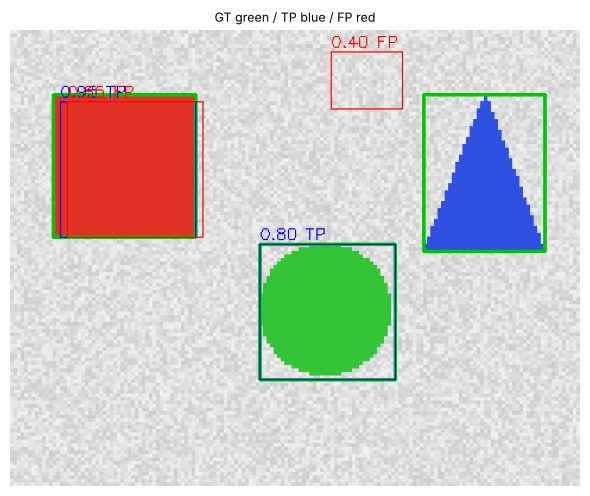

In [5]:
# ============================================================
# 4. 그림으로 확인
# ============================================================
canvas = cv2.imread(str(DATA / "scene.png"))
# 표시용으로 3배 확대 (INTER_NEAREST : 픽셀을 그대로 복제)
scale = 3
canvas = cv2.resize(canvas, None, fx=scale, fy=scale, interpolation=cv2.INTER_NEAREST)
for g in truth.itertuples():
    cv2.rectangle(canvas, (g.x1*scale, g.y1*scale), (g.x2*scale, g.y2*scale), (0, 200, 0), 2)
for p, res in zip(pred.itertuples(), table.result):
    color = (255, 0, 0) if res == "TP" else (0, 0, 255)
    cv2.rectangle(canvas, (p.x1*scale, p.y1*scale), (p.x2*scale, p.y2*scale), color, 1)
    cv2.putText(canvas, f"{p.confidence:.2f} {res}", (p.x1*scale, p.y1*scale-4), cv2.FONT_HERSHEY_SIMPLEX, 0.45, color, 1)
cv2.imwrite(str(OUT / "p02_matching.png"), canvas)
show([canvas], ["GT green / TP blue / FP red"], size=6)

## 5. IoU 기준을 바꾸면

같은 예측이라도 TP 판정 기준에 따라 결과가 달라진다. 기준 0.95에서는 square 예측(IoU 0.9025)도 FP가 된다.

In [6]:
# ============================================================
# 5. IoU 기준 비교
# ============================================================
rows = []
for th in [0.5, 0.75, 0.95]:
    t, u = match(pred, truth, th)
    rows.append(dict(iou_threshold=th, tp=len(u), fp=len(pred)-len(u), fn=len(truth)-len(u)))
pd.DataFrame(rows)

,iou_threshold,tp,fp,fn
0,0.50,2,2,1
1,0.75,2,2,1
2,0.95,1,3,2


## 정리 (README 설명 질문)

- **같은 정답에 박스 두 개가 겹치면 왜 둘 다 TP가 아닌가?** 정답 하나는 한 번만 TP로 쓸 수 있다. 점수가 높은 0.95 예측이 먼저 정답을 차지하고, 0.85 예측은 IoU 0.8162로 충분히 겹쳐도 중복(FP)이 된다.
- **confidence와 IoU는 왜 다른가?** confidence는 모델이 스스로 매긴 확신 점수이고, IoU는 정답과 비교한 위치 겹침이다. 0.80 circle은 IoU 1.0이지만, 0.40 triangle은 IoU 0이다.